# Does the stress effect on risky choice depend on presentation order?

The paper's probit (RNP) model with **presentation order** (risky first vs. safe first)
added as a factor, fitting the full group × session × order interaction.

| Model | Formula | Role |
| --- | --- | --- |
| `paper` | `chose_risky ~ x*session*group + (x*session\|subject)` | The paper model, refit in the current bambi as a check against `bambi-RNP-fit_trace_model1` |
| `order` | `chose_risky ~ x*session*group*order + (x*session\|subject)` | **The requested model**: random effects as in the paper model |
| `order_re` | `chose_risky ~ x*session*group*order + (x*session*order\|subject)` | Sensitivity check: order varies *within* subject, so it also gets by-subject slopes |

`x = log(risky/safe)`, probit link. `session` is numeric 1/2 and `group` and `order` are numeric 0/1
(`order = 1` means risky first), as in the paper model. The priors are bambi's defaults (the paper's
"standard weakly informative priors"), and the sampler settings are the paper notebook's.

**Fits** are in `fit_probit_order.py` (10–15 min each on a laptop, run in parallel), which writes
`derivatives/cogmodels/bambi-RNP-fit_trace_model-{paper,order,order_re}.netcdf`.
This notebook only loads them:

```bash
cd stress_risk/analyse_results
for m in paper order order_re; do python fit_probit_order.py $m --bids_folder <bids_folder> & done
```

Run with this directory as the working directory. Ran 2026-09-28 in `risk7t` (bambi 0.15.0, pymc 5.25.1),
because there is no `behav_fit` env on that machine. The paper trace was fit with bambi 0.9.2 / pymc 4.3.0,
which is why the `paper` refit is here.

In [1]:
import os.path as op
import sys

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, op.abspath(op.join('..', '..')))   # the stress_risk package, if not pip-installed
from fit_probit_order import FORMULAE, build, get_model_data, trace_path

bids_folder = '/Users/gdehol/data/ds-stressrisk'
out_folder = '/Users/gdehol/git/stress_risk/notes/rebuttal1/results'

sns.set_theme('paper', 'white', font='helvetica', font_scale=1.5, palette='tab10')

/Users/gdehol/git/stress_risk/stress_risk/utils/data.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


## Data

The paper's trial-level choice data (`stress_risk.utils.data.get_data`), 11,891 trials from 50 subjects (25 per group). Order is balanced within every subject × session.

In [2]:
df = get_model_data(bids_folder)
print(f"{len(df)} trials, {df.subject.nunique()} subjects, "
      f"{df.groupby('group').subject.nunique().to_dict()} per group")

raw = df.groupby(['order', 'group', 'session']).chose_risky.mean().unstack('session')
raw['session change'] = raw[2] - raw[1]
raw.index = raw.index.set_levels([['Safe first', 'Risky first'], ['Control', 'Stress']])
raw

Found 50 subjects


/Users/gdehol/git/stress_risk/stress_risk/utils/data.py:224: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '20%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '32%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '44%', '56%', '56%', '56%', '56%', '56%', '56%', '56%', '56%

11891 trials, 50 subjects, {0: 25, 1: 25} per group


session                     1         2  session change
order       group                                      
Safe first  Control  0.506729  0.525606        0.018877
            Stress   0.444370  0.554136        0.109766
Risky first Control  0.521212  0.550910        0.029698
            Stress   0.453378  0.558902        0.105524

In [3]:
# Raw difference-in-difference of P(risky), per order (no model)
did_raw = raw['session change'].xs('Stress', level=1) - raw['session change'].xs('Control', level=1)
did_raw.to_frame('stress effect on P(risky), raw')

,"stress effect on P(risky), raw"
order,
Safe first,0.090889
Risky first,0.075826


## Traces and convergence

In [4]:
traces = {label: az.from_netcdf(trace_path(label, bids_folder)) for label in FORMULAE}
traces['paper (stored, bambi 0.9.2)'] = az.from_netcdf(
    op.join(bids_folder, 'derivatives', 'cogmodels', 'bambi-RNP-fit_trace_model1.netcdf'))

rows = []
for label, t in traces.items():
    s = az.summary(t, kind='diagnostics')
    for part, keep in [('population', ~s.index.str.contains('|', regex=False)),
                       ('subject sigmas', s.index.str.endswith('_sigma')),
                       ('subject offsets', s.index.str.contains('|subject[', regex=False))]:
        ss_ = s[keep]
        rows.append(dict(model=label, parameters=part, n=len(ss_), max_rhat=ss_.r_hat.max(),
                         min_ess_bulk=ss_.ess_bulk.min(), min_ess_tail=ss_.ess_tail.min(),
                         divergences=int(t.sample_stats.diverging.sum())))
pd.DataFrame(rows).set_index(['model', 'parameters']).round(3)

n  max_rhat  min_ess_bulk  \
model                       parameters                                     
paper                       population         8      1.00        1750.0   
                            subject sigmas     4      1.00         816.0   
                            subject offsets  200      1.00        1043.0   
order                       population        16      1.00        1046.0   
                            subject sigmas     4      1.01         663.0   
                            subject offsets  200      1.01         861.0   
order_re                    population        16      1.00         742.0   
                            subject sigmas     8      1.01         578.0   
                            subject offsets  400      1.01         690.0   
paper (stored, bambi 0.9.2) population         8      1.00        1748.0   
                            subject sigmas     4      1.01         758.0   
                            subject offsets  200      1.01        1121.0   

                                             min_ess_tail  divergences  
model                       parameters                                  
paper                       population             2212.0            0  
                            subject sigmas         1281.0            0  
                            subject offsets        1490.0            0  
order                       population             1498.0            0  
                            subject sigmas          679.0            0  
                            subject offsets         904.0            0  
order_re                    population             1493.0            0  
                            subject sigmas          512.0            0  
                            subject offsets         982.0            0  
paper (stored, bambi 0.9.2) population             2230.0            0  
                            subject sigmas          741.0            0  
                            subject offsets        1009.0            0

## Population-level parameters per cell

For each group × session (× order) cell, the population-level (random effects at zero) probit
intercept δ and slope γ are sums of coefficients weighted by the covariate values. RNP is computed as in
the paper: `clip(exp(δ/γ), 0, 1)`. This is the same quantity as
`stress_risk.behavior.utils.extract_rnp_precision(..., group=True)`, computed from the coefficients
directly so that it does not depend on the bambi version.

In [5]:
FACTORS = {'Intercept', 'x', 'session', 'group', 'order'}


def cell_params(idata, session, group, order=0):
    # delta (probit value at x = 0) and gamma (slope on x) per posterior draw
    post = idata.posterior
    cov = dict(session=session, group=group, order=order)
    delta = gamma = 0.
    for name in post.data_vars:
        factors = name.split(':')
        if '|' in name or not set(factors) <= FACTORS:
            continue
        w = np.prod([cov[f] for f in factors if f not in ('Intercept', 'x')])
        v = post[name].values.ravel() * w
        if 'x' in factors:
            gamma = gamma + v
        else:
            delta = delta + v
    return delta, gamma


def rnp(idata, session, group, order=0):
    d, g = cell_params(idata, session, group, order)
    return np.clip(np.exp(d / g), 0, 1)


def stress_effect(idata, order=0, kind='rnp'):
    # (stress: ses2 - ses1) - (control: ses2 - ses1), per draw
    if kind == 'rnp':
        f = lambda s, g: rnp(idata, s, g, order)
    else:
        i = 0 if kind == 'delta' else 1
        f = lambda s, g: cell_params(idata, s, g, order)[i]
    return (f(2, 1) - f(1, 1)) - (f(2, 0) - f(1, 0))


def summarize(samples, name=None):
    samples = np.asarray(samples)
    m = samples.mean()
    return pd.Series(dict(mean=m, ci_lo=np.percentile(samples, 2.5), ci_hi=np.percentile(samples, 97.5),
                          # the paper's Bayesian p: share of the posterior on the other side of 0
                          p_bayes=np.mean(samples < 0) if m > 0 else np.mean(samples > 0)), name=name)

### Check: the refit paper model reproduces the reported result

Paper: RNP group × session interaction mean = 0.07, 95% CI [−0.01, 0.14], p_bayes = 0.034; stress group
RNP from ≈47% to 55.6%, control ≈49.7% to 50.9%.

In [6]:
check = []
for label in ['paper (stored, bambi 0.9.2)', 'paper']:
    t = traces[label]
    check.append(summarize(stress_effect(t, kind='rnp'), (label, 'RNP stress effect')))
    check.append(summarize(stress_effect(t, kind='gamma'), (label, 'slope stress effect')))
    for g, gname in [(0, 'control'), (1, 'stress')]:
        for s in [1, 2]:
            check.append(summarize(rnp(t, s, g), (label, f'RNP {gname} ses-{s}')))
pd.DataFrame(check).round(3)

mean  ci_lo  ci_hi  p_bayes
paper (stored, bambi 0.9.2) RNP stress effect    0.066 -0.005  0.142    0.034
                            slope stress effect -0.050 -0.504  0.377    0.418
                            RNP control ses-1    0.497  0.410  0.589    0.000
                            RNP control ses-2    0.510  0.402  0.627    0.000
                            RNP stress ses-1     0.477  0.381  0.576    0.000
                            RNP stress ses-2     0.556  0.422  0.693    0.000
paper                       RNP stress effect    0.066 -0.004  0.137    0.031
                            slope stress effect -0.053 -0.468  0.373    0.408
                            RNP control ses-1    0.494  0.410  0.579    0.000
                            RNP control ses-2    0.505  0.401  0.612    0.000
                            RNP stress ses-1     0.475  0.382  0.573    0.000
                            RNP stress ses-2     0.553  0.424  0.690    0.000

## (1) The stress effect separately for each presentation order

Stress effect = group × session difference-in-difference, (stress: session 2 − session 1) −
(control: session 2 − session 1), on:

* **RNP**, the paper's headline measure;
* **slope** γ (choice consistency);
* **intercept** δ, the probit value at equal payoffs (x = 0). For safe first this is the
  `session:group` coefficient; for risky first it is `session:group + session:group:order`.

In [7]:
res = []
for label in ['order', 'order_re']:
    t = traces[label]
    for o, oname in [(0, 'Safe first'), (1, 'Risky first')]:
        for kind, kname in [('rnp', 'RNP'), ('gamma', 'slope'), ('delta', 'intercept')]:
            res.append(summarize(stress_effect(t, o, kind), (label, oname, kname)))
per_order = pd.DataFrame(res)
per_order.index.names = ['model', 'order', 'measure']
per_order.round(3)

mean  ci_lo  ci_hi  p_bayes
model    order       measure                                
order    Safe first  RNP        0.069  0.003  0.140    0.021
                     slope     -0.168 -0.682  0.344    0.258
                     intercept  0.419 -0.026  0.873    0.036
         Risky first RNP        0.061 -0.017  0.144    0.064
                     slope      0.084 -0.441  0.612    0.375
                     intercept  0.184 -0.283  0.637    0.214
order_re Safe first  RNP        0.070  0.004  0.141    0.018
                     slope     -0.139 -0.657  0.393    0.308
                     intercept  0.403 -0.040  0.872    0.039
         Risky first RNP        0.060 -0.021  0.146    0.074
                     slope      0.064 -0.472  0.593    0.408
                     intercept  0.200 -0.260  0.681    0.196

In [8]:
# RNP per cell, order model
cells = []
for o, oname in [(0, 'Safe first'), (1, 'Risky first')]:
    for g, gname in [(0, 'Control'), (1, 'Stress')]:
        for s in [1, 2]:
            cells.append(summarize(rnp(traces['order'], s, g, o), (oname, gname, s)))
cells = pd.DataFrame(cells)
cells.index.names = ['order', 'group', 'session']
cells[['mean', 'ci_lo', 'ci_hi']].round(3)

mean  ci_lo  ci_hi
order       group   session                     
Safe first  Control 1        0.490  0.407  0.576
                    2        0.498  0.403  0.600
            Stress  1        0.472  0.382  0.568
                    2        0.549  0.427  0.678
Risky first Control 1        0.501  0.413  0.593
                    2        0.518  0.401  0.646
            Stress  1        0.478  0.385  0.574
                    2        0.556  0.426  0.697

## (2) The group × session × order interaction

The four-way coefficients carry the three-way interaction:

* `session:group:order` = the difference in the intercept stress effect between orders (risky first − safe first);
* `x:session:group:order` = the same for the slope.

The derived quantity on the paper's scale is the difference between orders in the RNP stress effect.

In [9]:
res = []
for label in ['order', 'order_re']:
    t = traces[label]
    for var in ['session:group:order', 'x:session:group:order']:
        res.append(summarize(t.posterior[var].values.ravel(), (label, var)))
    res.append(summarize(stress_effect(t, 1, 'rnp') - stress_effect(t, 0, 'rnp'),
                         (label, 'RNP stress effect, risky first - safe first')))
three_way = pd.DataFrame(res)
three_way.index.names = ['model', 'quantity']
three_way.round(3)

mean  ci_lo  ci_hi  \
model    quantity                                                           
order    session:group:order                         -0.235 -0.700  0.223   
         x:session:group:order                        0.253 -0.336  0.847   
         RNP stress effect, risky first - safe first -0.008 -0.060  0.043   
order_re session:group:order                         -0.203 -0.667  0.263   
         x:session:group:order                        0.203 -0.413  0.810   
         RNP stress effect, risky first - safe first -0.009 -0.061  0.044   

                                                      p_bayes  
model    quantity                                              
order    session:group:order                            0.154  
         x:session:group:order                          0.199  
         RNP stress effect, risky first - safe first    0.382  
order_re session:group:order                            0.192  
         x:session:group:order                          0.242  
         RNP stress effect, risky first - safe first    0.363

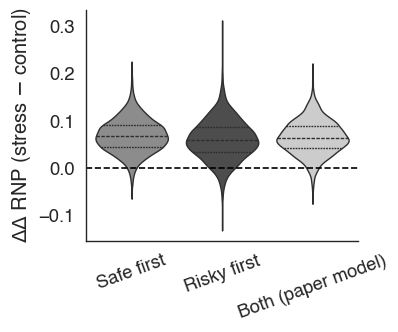

In [10]:
# Posterior of the RNP stress effect by order, next to the paper model's
sns.set_theme('paper', 'white', font='helvetica', font_scale=1.5, palette='tab10')
t = traces['order']
post = pd.concat([pd.DataFrame({'Stress effect on RNP': stress_effect(t, o, 'rnp'), 'Order': oname})
                  for o, oname in [(0, 'Safe first'), (1, 'Risky first')]] +
                 [pd.DataFrame({'Stress effect on RNP': stress_effect(traces['paper'], kind='rnp'),
                                'Order': 'Both (paper model)'})])

fig, ax = plt.subplots(figsize=(3.5, 3))
sns.violinplot(post, x='Order', y='Stress effect on RNP', hue='Order', palette=['0.55', '0.3', '0.8'],
               inner='quartile', cut=0, ax=ax, legend=False)
ax.axhline(0, c='k', ls='--')
ax.set(xlabel=None, ylabel=r'$\Delta\Delta$ RNP (stress $-$ control)')
ax.tick_params(axis='x', rotation=20)
sns.despine()
for ext in ['pdf', 'png']:
    fig.savefig(op.join(out_folder, f'fig_probit_order_stress_effect.{ext}'), bbox_inches='tight', dpi=220)

## Figure: risky choices per stake, by group, session and order (Figure 3B style)

Same layout as Figure 3B (`behavior.utils.plot_ppc(..., level='group', plot_type=6)`): x-axis is the safe
offer (stake), columns are order, rows are group, colours are session. Dots are the observed proportions.
Lines and bands are the posterior predictive mean and 95% HDI of the **order probit model**: predictions
are averaged within subject and then across subjects, with every 10th draw used.

Note that the probit model has **no stake term**. It sees stake only through the payoff ratios offered
at each stake, so it cannot capture the stake dependence that the PMC model explains in Figure 3B. The
figure shows how much of the pattern an order-aware probit gets without it.

In [11]:
model = build('order', df)
thin = traces['order'].sel(draw=slice(None, None, 10))
pps = model.predict(thin, kind='response', data=df, inplace=False)
pps = pps.posterior_predictive['chose_risky'].stack(sample=('chain', 'draw')).values   # (trial, sample)

keys = ['group', 'session', 'order', 'n_safe']
pred = pd.DataFrame(pps, index=pd.MultiIndex.from_frame(df[['subject'] + keys])).astype(float)
pred = pred.groupby(['subject'] + keys).mean().groupby(keys).mean()          # within subject, then across

hdi = np.array([az.hdi(row, hdi_prob=.95) for row in pred.values])
summary = pd.DataFrame({'p_predicted': pred.mean(1), 'hdi025': hdi[:, 0], 'hdi975': hdi[:, 1]}, index=pred.index)
summary = summary.join(df.groupby(keys).chose_risky.mean()).reset_index()
summary['Order'] = summary['order'].map({0: 'Safe first', 1: 'Risky first'})
summary['group'] = summary['group'].map({0: 'Control', 1: 'Stress'})
summary['Safe offer'] = summary['n_safe'].astype(int)
summary['Prop. chosen risky'] = summary['chose_risky'].astype(float)

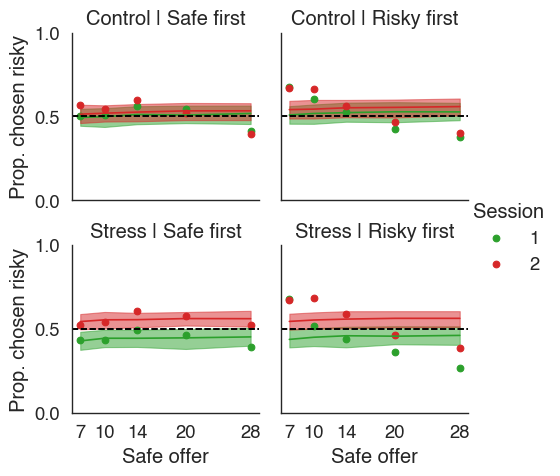

In [12]:
from stress_risk.behavior.utils import plot_prediction

sns.set_theme('paper', 'white', font='helvetica', font_scale=1.5, palette='tab10')
fac = sns.FacetGrid(summary, col='Order', col_order=['Safe first', 'Risky first'], hue='session',
                    row='group', palette=sns.color_palette()[2:], height=2.5, aspect=1)
fac.map_dataframe(plot_prediction, x='Safe offer')
fac.map(plt.scatter, 'Safe offer', 'Prop. chosen risky')
fac.map(lambda *args, **kwargs: plt.axhline(.5, c='k', ls='--'))
fac.set_titles('{row_name} | {col_name}')
fac.set(xticks=sorted(summary['Safe offer'].unique()), yticks=[0, .5, 1], ylim=(0, 1))
fac.set_axis_labels('Safe offer', 'Prop. chosen risky')
fac.add_legend(title='Session')
for ext in ['pdf', 'png']:
    fac.savefig(op.join(out_folder, f'fig_probit_order_ppc.{ext}'), bbox_inches='tight', dpi=220)